# 01 · Análisis exploratorio

**Pregunta de negocio:** ¿podemos detectar al momento de la compra qué pedidos llegarán tarde, para ajustar la fecha prometida o priorizar su envío y así evitar reseñas negativas?

Este notebook revisa los datos antes de modelar:
- tamaño y balance del objetivo;
- cómo cambian los retrasos en el tiempo;
- cuánto afectan a la calificación;
- qué variables se relacionan con ellos.

La tabla base viene de PostgreSQL (`sql/05_export_model_base.sql`). Las cifras agregadas vienen de `sql/04_analysis.sql`.

In [1]:
import sys
sys.path.insert(0, "../src")

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd

from features import load_model_base
from plot_style import AQUA, BLUE, GRAY, INK_2, ORANGE, apply_style

apply_style()
FIG_DIR = "../reports/figures"
SQL_DIR = "../reports/sql_results"

df = load_model_base("../data/processed/model_base.csv")
print(f"Pedidos con resultado de entrega conocido: {len(df):,}")
print(f"Periodo de compra: {df.purchase_ts.min():%Y-%m-%d} a {df.purchase_ts.max():%Y-%m-%d}")

Pedidos con resultado de entrega conocido: 97,300
Periodo de compra: 2017-01-05 a 2018-08-29


## 1. Balance del objetivo

`is_late = 1` cuando el pedido no llegó a tiempo:
- **late:** se entregó después del día prometido;
- **not_delivered:** se envió pero nunca registró entrega, y al corte de los datos ya había pasado su fecha prometida.

In [2]:
balance = (
    df.groupby("delivery_status")
    .size()
    .rename("pedidos")
    .to_frame()
    .assign(porcentaje=lambda t: (100 * t.pedidos / t.pedidos.sum()).round(2))
    .sort_values("pedidos", ascending=False)
)
print(f"Tasa de pedidos no entregados a tiempo: {df.is_late.mean():.2%}")
balance

Tasa de pedidos no entregados a tiempo: 7.84%


,pedidos,porcentaje
delivery_status,,
on_time,89672,92.16
late,6531,6.71
not_delivered,1097,1.13


Las clases están muy desbalanceadas: menos de 8% de los pedidos llegan tarde. Por eso, en el modelo se usa **AUC-PR**, y sobre todo **qué porcentaje de los retrasos se captura revisando un porcentaje fijo de pedidos**, en lugar de la exactitud. Un modelo que dijera "nunca hay retraso" tendría 92% de exactitud y no serviría de nada.

## 2. Los retrasos cambian mucho en el tiempo

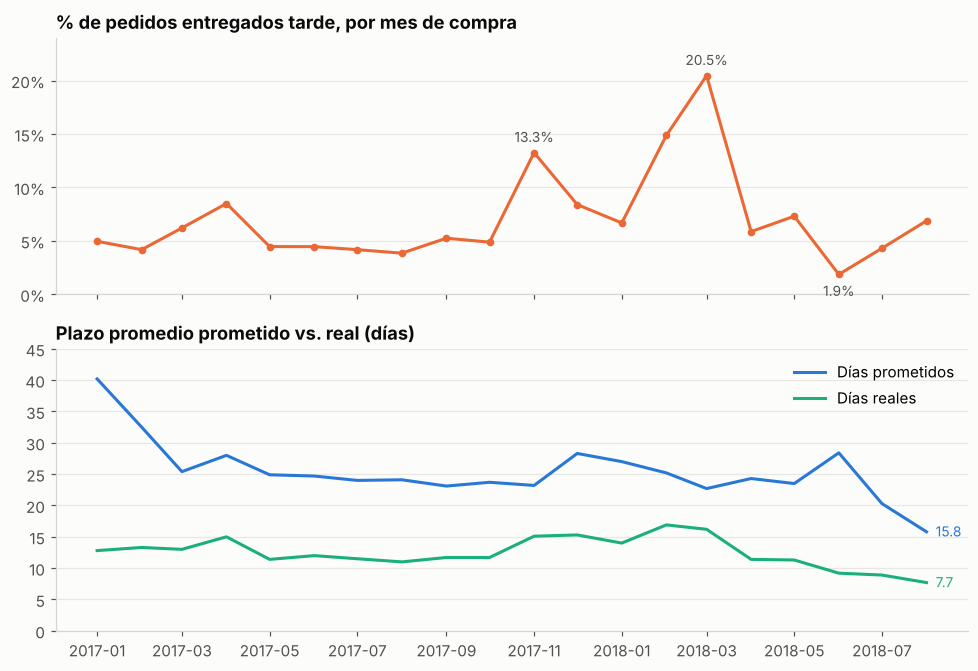

In [3]:
monthly = pd.read_csv(f"{SQL_DIR}/q1_monthly_kpis.csv", parse_dates=["month"])
monthly["late_pct"] = 100 - monthly["on_time_pct"]

fig, axes = plt.subplots(2, 1, figsize=(9, 6.2), sharex=True, gridspec_kw={"height_ratios": [1, 1.1]})
ax = axes[0]
ax.plot(monthly.month, monthly.late_pct, color=ORANGE, marker="o", markersize=4)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title("% de pedidos entregados tarde, por mes de compra")
for m, dy in [("2017-11-01", 7), ("2018-03-01", 7), ("2018-06-01", -14)]:
    r = monthly[monthly.month == m].iloc[0]
    ax.annotate(f"{r.late_pct:.1f}%", (r.month, r.late_pct), textcoords="offset points",
                xytext=(0, dy), ha="center", color=INK_2, fontsize=9)
ax.set_ylim(0, 24)

ax = axes[1]
ax.plot(monthly.month, monthly.avg_promised_days, color=BLUE, label="Días prometidos")
ax.plot(monthly.month, monthly.avg_actual_days, color=AQUA, label="Días reales")
ax.set_title("Plazo promedio prometido vs. real (días)")
ax.legend(loc="upper right")
ax.set_ylim(0, 45)
for line, col in [("avg_promised_days", BLUE), ("avg_actual_days", AQUA)]:
    last = monthly.iloc[-1]
    ax.annotate(f"{last[line]:.1f}", (last.month, last[line]), textcoords="offset points",
                xytext=(6, -3), color=col, fontsize=9)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/01_monthly_late_and_promise.png", dpi=160)

Hay tres cosas que condicionan todo el modelado:

1. **Picos de retraso.** Hubo un pico en noviembre de 2017 (Black Friday) y otro, más fuerte, en febrero y marzo de 2018: ahí la entrega real se alargó, pero el plazo prometido no.
2. **Plazos prometidos más cortos.** Desde mediados de 2018 Olist prometió plazos cada vez más cortos (de ~24 a ~16 días), mientras la entrega real también se aceleró.
3. **Cambio de régimen.** Un modelo entrenado con 2017 y principios de 2018 se evalúa en un periodo con otras reglas. Por eso la validación es **temporal** y además se hace un **backtest mes a mes**.

## 3. El retraso destruye la calificación

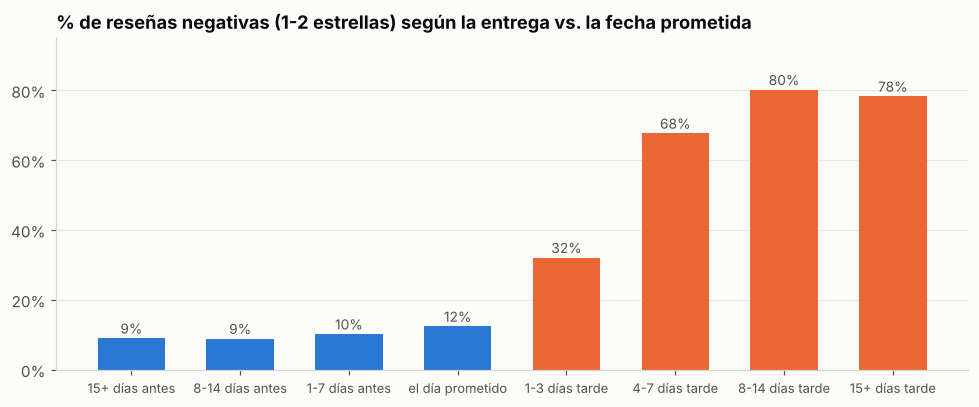

,valor
total_reviews,96584.0
total_negatives,12939.0
late_reviews,7402.0
late_negatives,4692.0
neg_rate_on_time_pct,9.2
neg_rate_late_pct,63.4
excess_negatives_from_delays,4008.0
excess_share_of_all_negatives_pct,31.0


In [4]:
by_days = pd.read_csv(f"{SQL_DIR}/q3_review_by_days_late.csv")
by_days["label"] = by_days.bucket.str[4:]
colors = [BLUE if "antes" in b or "prometido" in b else ORANGE for b in by_days.bucket]

fig, ax = plt.subplots(figsize=(9, 3.8))
bars = ax.bar(by_days.label, by_days.negative_pct, color=colors, width=0.62)
for b, v in zip(bars, by_days.negative_pct):
    ax.annotate(f"{v:.0f}%", (b.get_x() + b.get_width() / 2, v), textcoords="offset points",
                xytext=(0, 3), ha="center", fontsize=9, color=INK_2)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title("% de reseñas negativas (1-2 estrellas) según la entrega vs. la fecha prometida")
ax.tick_params(axis="x", labelsize=8.5)
ax.set_ylim(0, 95)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/02_negative_reviews_by_days_late.png", dpi=160)

attribution = pd.read_csv(f"{SQL_DIR}/q4_negative_reviews_attribution.csv").T.rename(columns={0: "valor"})
attribution

- **A tiempo:** con entrega puntual, solo ~9% de las reseñas son negativas.
- **Pocos días tarde ya pesan:** con 1 a 3 días de retraso sube a 32%, y con 4 o más días pasa del 67%.
- **Peso total:** los retrasos generan unas **4,000 reseñas negativas adicionales, el 31% de todas** las reseñas negativas del periodo.

**Conclusión: el problema vale la pena.**

## 4. ¿Qué se relaciona con el retraso?

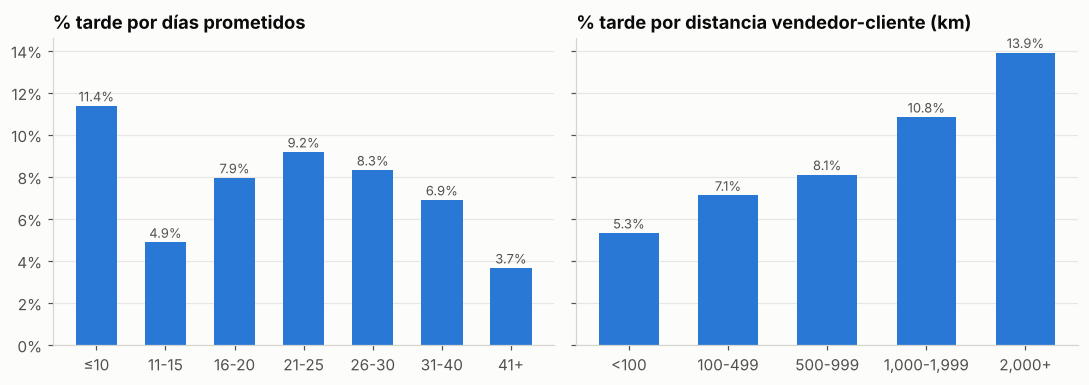

In [5]:
df["promise_bucket"] = pd.cut(df.promised_days, [0, 10, 15, 20, 25, 30, 40, 200],
                              labels=["≤10", "11-15", "16-20", "21-25", "26-30", "31-40", "41+"])
df["distance_bucket"] = pd.cut(df.max_distance_km, [-1, 100, 500, 1000, 2000, 5000],
                               labels=["<100", "100-499", "500-999", "1,000-1,999", "2,000+"])

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, col, title in [(axes[0], "promise_bucket", "Días prometidos"),
                       (axes[1], "distance_bucket", "Distancia vendedor-cliente (km)")]:
    rate = df.groupby(col, observed=True).is_late.mean() * 100
    ax.bar(rate.index.astype(str), rate.values, color=BLUE, width=0.6)
    for i, v in enumerate(rate.values):
        ax.annotate(f"{v:.1f}%", (i, v), textcoords="offset points", xytext=(0, 3),
                    ha="center", fontsize=8.5, color=INK_2)
    ax.set_title(f"% tarde por {title.lower()}")
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
fig.tight_layout()

La distancia sube el riesgo, como se esperaba. Pero el plazo prometido, **por sí solo**, casi no lo separa, porque los plazos largos se dan justo en las rutas largas.

Lo que importa es el **colchón**: el plazo prometido comparado con lo que normalmente tarda esa ruta. Esa variable se construye en el notebook 02.

In [6]:
states = pd.read_csv(f"{SQL_DIR}/q5_by_customer_state.csv")
states[["late_rank", "state", "orders", "late_pct", "avg_promised_days", "avg_actual_days", "avg_distance_km", "avg_review"]].head(8)

,late_rank,state,orders,late_pct,avg_promised_days,avg_actual_days,avg_distance_km,avg_review
0,1,AL,405,23.2,33.0,24.5,1830,3.79
1,2,MA,730,19.5,30.9,21.5,2105,3.79
2,3,SE,341,17.6,31.2,21.4,1651,3.84
3,4,CE,1310,16.3,31.7,21.2,2188,3.89
4,5,PI,482,15.1,30.6,19.4,1958,3.97
5,6,RJ,12598,14.2,26.9,15.2,490,3.92
6,7,BA,3321,14.0,30.0,19.3,1347,3.90
7,8,PA,961,13.0,37.7,23.7,2283,3.87


Río de Janeiro (RJ) es un caso revelador: está cerca de los vendedores (490 km en promedio), pero tiene 14% de retrasos, casi el triple que São Paulo. La distancia no lo explica todo; la ruta concreta sí importa. Por eso se calcula el historial **por ruta** (estado del vendedor → estado del cliente).

In [7]:
pareto = pd.read_csv(f"{SQL_DIR}/q6_seller_pareto.csv")
share_50 = pareto.loc[pareto.cum_late_share_pct >= 50, "cum_sellers_pct"].iloc[0]
share_80 = pareto.loc[pareto.cum_late_share_pct >= 80, "cum_sellers_pct"].iloc[0]
print(f"El {share_50:.1f}% de los vendedores concentra el 50% de los pedidos tardíos.")
print(f"El {share_80:.1f}% de los vendedores concentra el 80%.")

El 3.4% de los vendedores concentra el 50% de los pedidos tardíos.
El 13.9% de los vendedores concentra el 80%.


## 5. Calidad de los datos

In [8]:
quality = pd.DataFrame({
    "nulos": df.isna().sum(),
    "% nulos": (100 * df.isna().mean()).round(2),
})
quality[quality.nulos > 0]

,nulos,% nulos
delivered_ts,1097,1.13
review_score,716,0.74
days_vs_estimate,1097,1.13
max_distance_km,486,0.50
customer_lat,273,0.28
customer_lng,273,0.28
main_photos_qty,1380,1.42
total_weight_g,16,0.02
total_volume_cm3,16,0.02
distance_bucket,486,0.50


Notas de calidad:

- **Columnas de resultado:** `delivered_ts`, `days_vs_estimate` y `review_score` solo faltan donde es lógico (pedidos no entregados o sin reseña). Nunca entran como variables del modelo.
- **Distancia:** falta en ~0.5% de los pedidos, porque el código postal no aparece en la tabla de geolocalización. El modelo lo imputa con la mediana o lo maneja de forma nativa.
- **Códigos postales:** venían sin ceros a la izquierda en clientes y vendedores; se corrigió en SQL con `LPAD` (ver `sql/03_star_schema.sql`).
- **Fecha estimada:** siempre es 00:00, así que el retraso se mide por día calendario.